# **Day 8 :EDA**

In [1]:
from google.colab import files

uploaded = files.upload()  # Select kaggle.json from your computer

Saving kaggle (1).json to kaggle (1).json


In [2]:
import os
import shutil

os.makedirs('/root/.kaggle', exist_ok=True)

# Handle case where file was uploaded with duplicate suffix 'kaggle (1).json'
if os.path.exists('kaggle.json'):
    shutil.move('kaggle.json', '/root/.kaggle/kaggle.json')
elif os.path.exists('kaggle (1).json'):
    shutil.move('kaggle (1).json', '/root/.kaggle/kaggle.json')
else:
    raise FileNotFoundError("Please upload your kaggle.json file first using the previous cell.")

os.chmod('/root/.kaggle/kaggle.json', 0o600)

print("Kaggle API configured successfully!")

Kaggle API configured successfully!


In [ ]:
!pip install -q kaggle

In [3]:
!kaggle datasets download -d sujithmandala/simple-rainfall-classification-dataset

Dataset URL: https://www.kaggle.com/datasets/sujithmandala/simple-rainfall-classification-dataset
License(s): CC-BY-SA-4.0
100% 804/804 [00:00<00:00, 2.03MB/s]



In [4]:
import zipfile
with zipfile.ZipFile('simple-rainfall-classification-dataset.zip', 'r') as zip_ref:
    zip_ref.extractall('rainfall_dataset')
import os
print(os.listdir('rainfall_dataset'))

['rainfall.csv']


In [5]:
import pandas as pd
df = pd.read_csv('rainfall_dataset/rainfall.csv')
display(df.head())

,date,rainfall,temperature,humidity,wind_speed,weather_condition
0,2022-01-01,12.5,15.2,78.0,8.5,Rainy
1,2022-01-02,8.2,17.8,65.0,5.2,Rainy
2,2022-01-03,0.0,20.1,52.0,3.1,Sunny
3,2022-01-04,3.7,18.6,71.0,6.7,Rainy
4,2022-01-05,21.1,14.8,82.0,9.3,Rainy


In [6]:
df.head(10)

,date,rainfall,temperature,humidity,wind_speed,weather_condition
0,2022-01-01,12.5,15.2,78.0,8.5,Rainy
1,2022-01-02,8.2,17.8,65.0,5.2,Rainy
2,2022-01-03,0.0,20.1,52.0,3.1,Sunny
3,2022-01-04,3.7,18.6,71.0,6.7,Rainy
4,2022-01-05,21.1,14.8,82.0,9.3,Rainy
5,2022-01-06,15.3,16.5,75.0,7.8,Rainy
6,2022-01-07,6.8,19.2,61.0,4.5,Rainy
7,2022-01-08,0.0,21.7,48.0,2.9,Sunny
8,2022-01-09,11.2,17.3,73.0,6.1,Rainy
9,2022-01-10,18.6,15.8,79.0,8.9,Rainy


In [7]:
df.shape

(54, 6)

In [8]:
df.columns

Index(['date', 'rainfall', 'temperature', 'humidity', 'wind_speed',
       'weather_condition'],
      dtype='object')

In [9]:
df.dtypes

,0
date,object
rainfall,float64
temperature,float64
humidity,float64
wind_speed,float64
weather_condition,object


In [10]:
df.isnull().sum()

,0
date,0
rainfall,1
temperature,1
humidity,1
wind_speed,1
weather_condition,1


In [11]:
print(df['rainfall'].mean())
print(df['rainfall'].median())
print(df['rainfall'].std())

9.049056603773584
8.3
6.712520524005565


In [12]:
print(df['temperature'].max())
print(df['temperature'].min())

23.4
13.9


In [13]:
df.select_dtypes(include='number')

,rainfall,temperature,humidity,wind_speed
0,12.5,15.2,78.0,8.5
1,8.2,17.8,65.0,5.2
2,0.0,20.1,52.0,3.1
3,3.7,18.6,71.0,6.7
4,21.1,14.8,82.0,9.3
5,15.3,16.5,75.0,7.8
6,6.8,19.2,61.0,4.5
7,0.0,21.7,48.0,2.9
8,11.2,17.3,73.0,6.1
9,18.6,15.8,79.0,8.9


In [14]:
df.select_dtypes(include='number').corr()

,rainfall,temperature,humidity,wind_speed
rainfall,1.000000,-0.790566,0.821357,0.733376
temperature,-0.790566,1.000000,-0.966097,-0.902996
humidity,0.821357,-0.966097,1.000000,0.951643
wind_speed,0.733376,-0.902996,0.951643,1.000000


<Axes: >

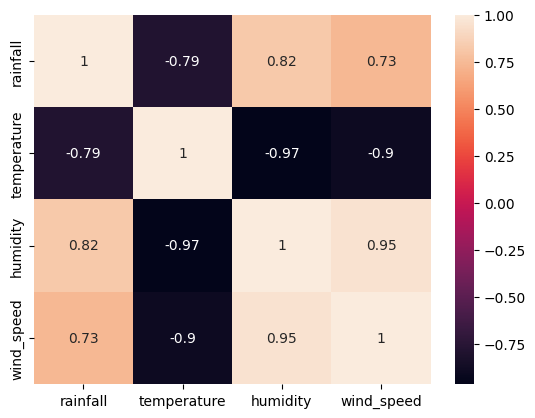

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.heatmap(df.select_dtypes(include='number').corr(), annot=True)

In [16]:
df.select_dtypes(include='number').corr()['rainfall'].sort_values()

,rainfall
temperature,-0.790566
wind_speed,0.733376
humidity,0.821357
rainfall,1.000000


In [17]:
corr_matrix = df.select_dtypes(include='number').corr().abs()
for i in range(len(corr_matrix.columns)):
    for j in range(i):
        if corr_matrix.iloc[i, j] > 0.7:
            print(corr_matrix.columns[i], corr_matrix.columns[j])

temperature rainfall
humidity rainfall
humidity temperature
wind_speed rainfall
wind_speed temperature
wind_speed humidity


In [18]:
highly_corr = []
corr_matrix = df.select_dtypes(include='number').corr().abs()
for i in range(len(corr_matrix.columns)):
    for j in range(i):
        if corr_matrix.iloc[i, j] > 0.7:
            highly_corr.append((corr_matrix.columns[i], corr_matrix.columns[j]))
print(highly_corr)

[('temperature', 'rainfall'), ('humidity', 'rainfall'), ('humidity', 'temperature'), ('wind_speed', 'rainfall'), ('wind_speed', 'temperature'), ('wind_speed', 'humidity')]


In [19]:
df_dropped = df.drop(columns=[pair[0] for pair in highly_corr] if highly_corr else [])

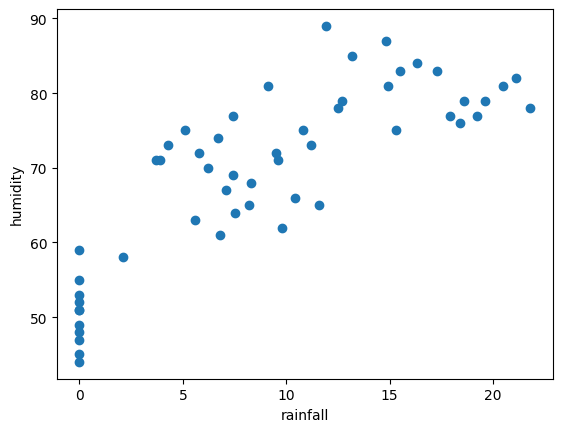

In [20]:
plt.scatter(df['rainfall'], df['humidity'])
plt.xlabel('rainfall')
plt.ylabel('humidity')
plt.show()

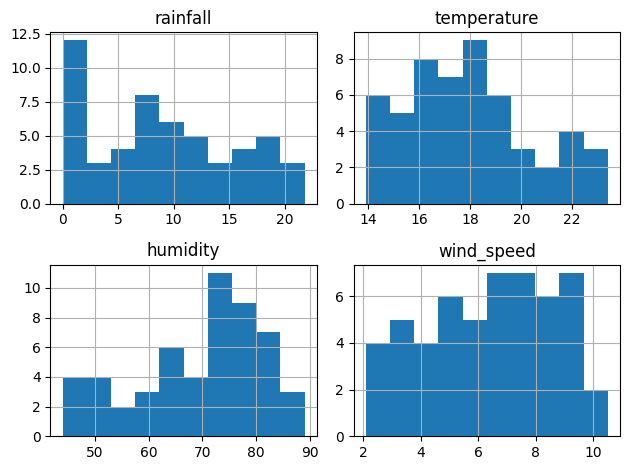

In [21]:
df.select_dtypes(include='number').hist()
plt.tight_layout()
plt.show()

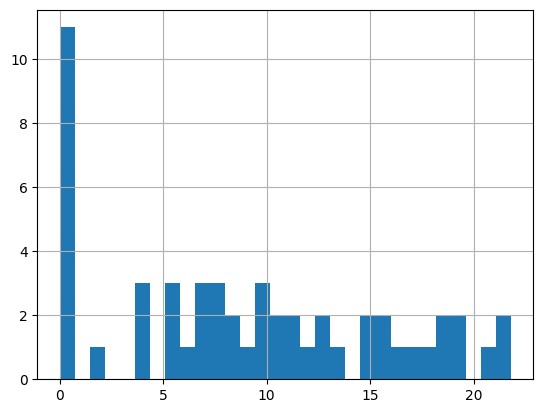

In [22]:
df['rainfall'].hist(bins=30)
plt.show()

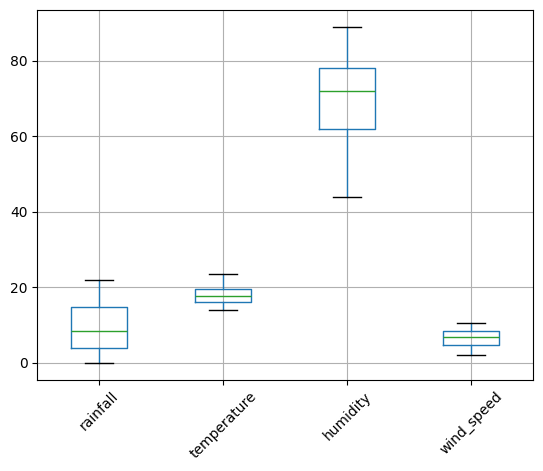

In [23]:
df.select_dtypes(include='number').boxplot()
plt.xticks(rotation=45)
plt.show()

In [24]:
q1 = df.select_dtypes(include='number').quantile(0.25)
q3 = df.select_dtypes(include='number').quantile(0.75)
iqr = q3 - q1
outliers = ((df.select_dtypes(include='number') < (q1 - 1.5 * iqr)) | (df.select_dtypes(include='number') > (q3 + 1.5 * iqr))).sum()
print(outliers)

rainfall       0
temperature    0
humidity       0
wind_speed     0
dtype: int64


In [25]:
df.select_dtypes(include='number').skew()

,0
rainfall,0.191925
temperature,0.436075
humidity,-0.564768
wind_speed,-0.207329


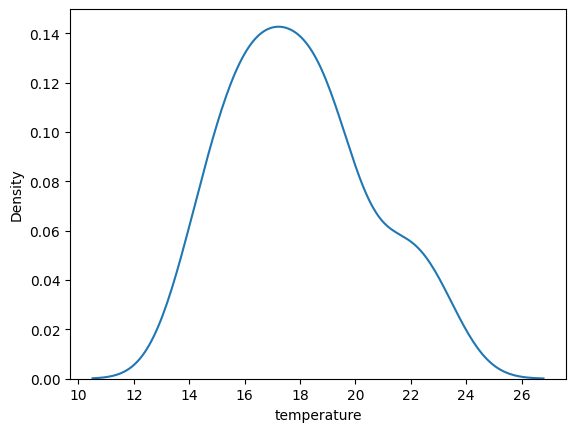

In [26]:
sns.kdeplot(df['temperature'].dropna())
plt.show()

In [27]:
print(df['rainfall'].mean() > df['rainfall'].median())

True


In [28]:
print((df.select_dtypes(include='number').skew() > 1).sum())

0


In [29]:
df.groupby('weather_condition')['rainfall'].mean()

,rainfall
weather_condition,
Rainy,11.419048
Sunny,0.000000


In [30]:
df.nlargest(3, 'rainfall')

,date,rainfall,temperature,humidity,wind_speed,weather_condition
29,2022-01-30,21.8,16.4,78.0,7.6,Rainy
4,2022-01-05,21.1,14.8,82.0,9.3,Rainy
44,2022-02-14,20.5,15.6,81.0,8.2,Rainy


In [31]:
df[df['rainfall'] > df['rainfall'].mean()]

,date,rainfall,temperature,humidity,wind_speed,weather_condition
0,2022-01-01,12.5,15.2,78.0,8.5,Rainy
4,2022-01-05,21.1,14.8,82.0,9.3,Rainy
5,2022-01-06,15.3,16.5,75.0,7.8,Rainy
8,2022-01-09,11.2,17.3,73.0,6.1,Rainy
9,2022-01-10,18.6,15.8,79.0,8.9,Rainy
10,2022-01-11,9.5,16.2,72.0,5.7,Rainy
14,2022-01-15,14.9,15.1,81.0,8.7,Rainy
15,2022-01-16,19.2,16.8,77.0,7.2,Rainy
18,2022-01-19,10.8,17.6,75.0,6.7,Rainy
19,2022-01-20,16.3,14.5,84.0,9.1,Rainy


In [32]:
mean_rain = df['rainfall'].mean()
print(df[df['rainfall'] > mean_rain]['temperature'].mean())
print(df[df['rainfall'] <= mean_rain]['temperature'].mean())

16.253846153846155
19.585185185185182


In [33]:
df['high_rainfall'] = (df['rainfall'] > df['rainfall'].mean()).astype(int)

In [34]:
df['high_rainfall'].value_counts()

,count
high_rainfall,
0,28
1,26


In [35]:
df[df['high_rainfall'] == 1].select_dtypes(include='number').corr()

,rainfall,temperature,humidity,wind_speed,high_rainfall
rainfall,1.000000,-0.345569,0.409248,0.324545,NaN
temperature,-0.345569,1.000000,-0.943597,-0.916880,NaN
humidity,0.409248,-0.943597,1.000000,0.940413,NaN
wind_speed,0.324545,-0.916880,0.940413,1.000000,NaN
high_rainfall,NaN,NaN,NaN,NaN,NaN


In [36]:
def find_outliers_iqr(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    return series[(series < (q1 - 1.5 * iqr)) | (series > (q3 + 1.5 * iqr))]

In [37]:
q1 = df['rainfall'].quantile(0.25)
q3 = df['rainfall'].quantile(0.75)
iqr = q3 - q1
df_no_outliers = df[(df['rainfall'] >= (q1 - 1.5 * iqr)) & (df['rainfall'] <= (q3 + 1.5 * iqr))]

In [38]:
num_cols = df.select_dtypes(include='number').columns
df_normalized = df.copy()
df_normalized[num_cols] = (df[num_cols] - df[num_cols].min()) / (df[num_cols].max() - df[num_cols].min())

In [39]:
num_cols = df.select_dtypes(include='number').columns
df_standardized = df.copy()
df_standardized[num_cols] = (df[num_cols] - df[num_cols].mean()) / df[num_cols].std()

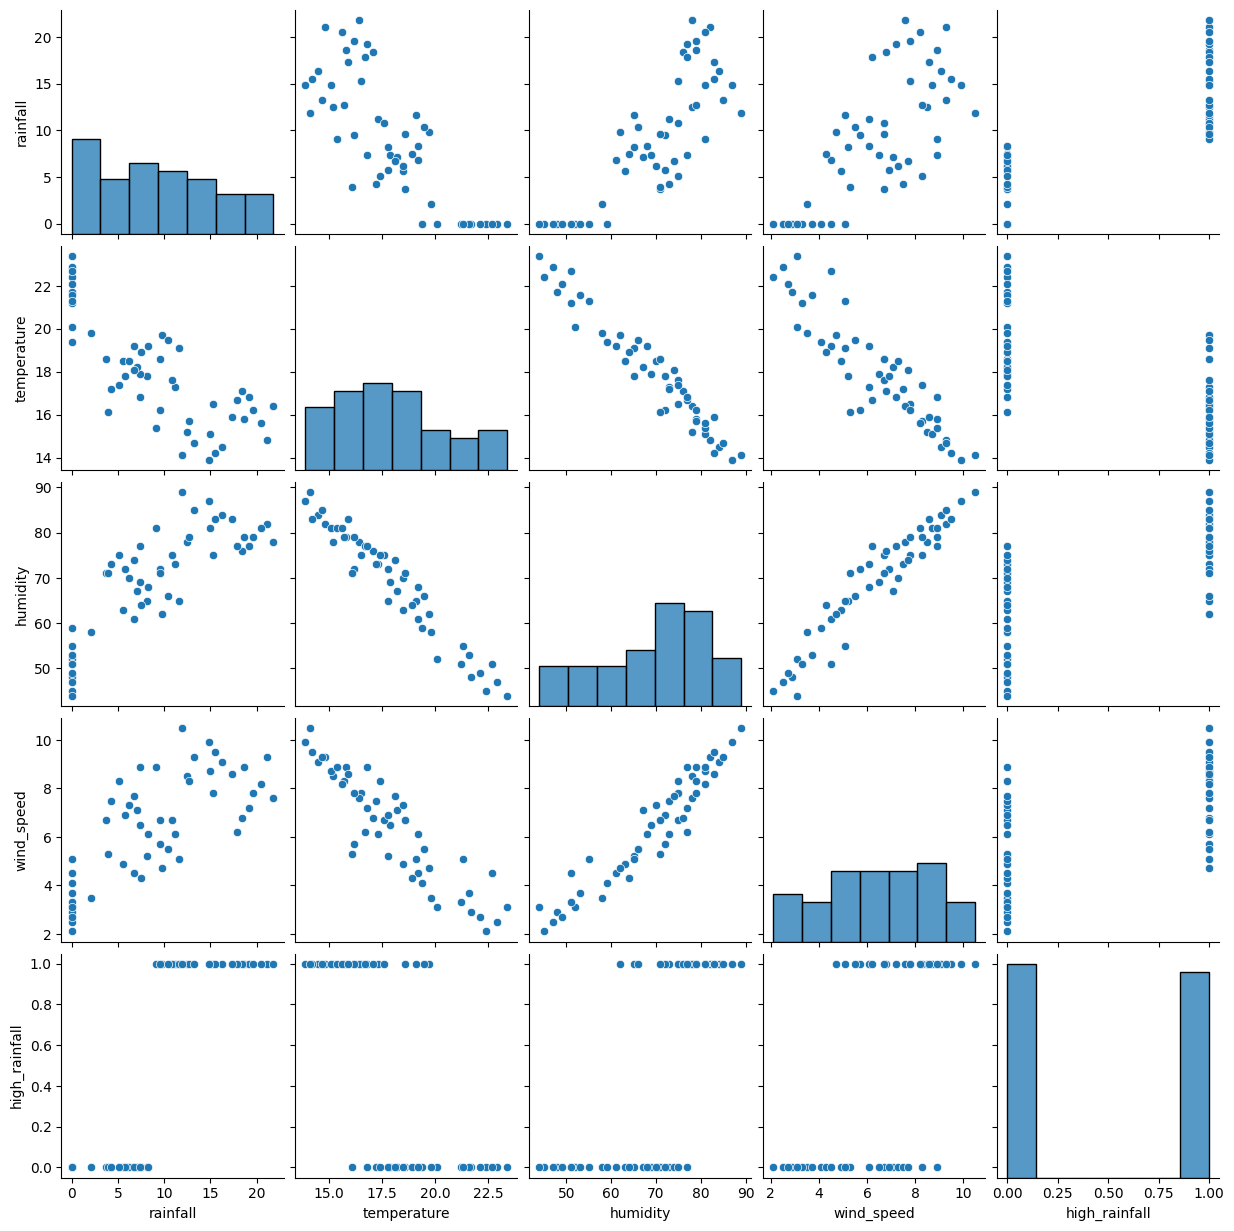

In [40]:
sns.pairplot(df.select_dtypes(include='number').dropna())
plt.show()

In [41]:
corr = df.select_dtypes(include='number').corr()['rainfall']
print(corr[corr.abs() > 0.5])

rainfall         1.000000
temperature     -0.790566
humidity         0.821357
wind_speed       0.733376
high_rainfall    0.841399
Name: rainfall, dtype: float64


In [42]:
df['weather_condition'].value_counts(normalize=True)

,proportion
weather_condition,
Rainy,0.792453
Sunny,0.207547


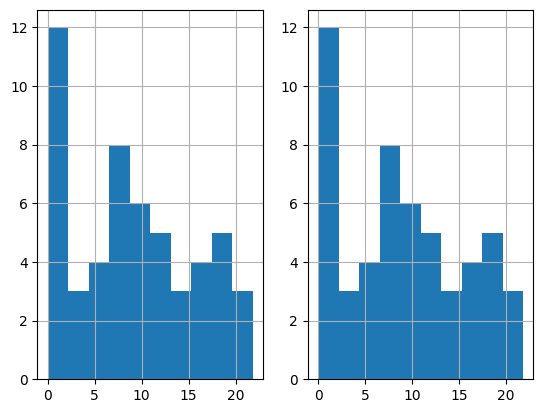

In [43]:
plt.subplot(1, 2, 1)
df['rainfall'].hist()
plt.subplot(1, 2, 2)
df_no_outliers['rainfall'].hist()
plt.show()

In [44]:
summary = pd.DataFrame({
    'mean': df.select_dtypes(include='number').mean(),
    'skew': df.select_dtypes(include='number').skew()
})
print(summary)

                    mean      skew
rainfall        9.049057  0.191925
temperature    17.950943  0.436075
humidity       69.245283 -0.564768
wind_speed      6.403774 -0.207329
high_rainfall   0.481481  0.076260


In [45]:
def full_eda(data):
    print(data.describe())
    print(data.select_dtypes(include='number').corr())
    data.select_dtypes(include='number').hist()
    plt.show()

In [ ]:
!kaggle datasets download -d brendan45774/test-file

Dataset URL: https://www.kaggle.com/datasets/brendan45774/test-file
License(s): CC0-1.0
100% 11.2k/11.2k [00:00<00:00, 33.6MB/s]



In [ ]:
import zipfile

# Extract the downloaded test-file.zip dataset
with zipfile.ZipFile('test-file.zip', 'r') as zip_ref:
    zip_ref.extractall('test_file_dataset')

print("Dataset extracted successfully to 'test_file_dataset' directory!")

Dataset extracted successfully to 'test_file_dataset' directory!


In [ ]:
import os

print(os.listdir('test_file_dataset'))

['tested.csv']


In [ ]:
import pandas as pd

# Replace filename with the actual CSV name printed above
df = pd.read_csv('test_file_dataset/tested.csv')

print(df.head())
print(df.shape)

   PassengerId  Survived  Pclass  \
0          892         0       3   
1          893         1       3   
2          894         0       2   
3          895         0       3   
4          896         1       3   

                                           Name     Sex   Age  SibSp  Parch  \
0                              Kelly, Mr. James    male  34.5      0      0   
1              Wilkes, Mrs. James (Ellen Needs)  female  47.0      1      0   
2                     Myles, Mr. Thomas Francis    male  62.0      0      0   
3                              Wirz, Mr. Albert    male  27.0      0      0   
4  Hirvonen, Mrs. Alexander (Helga E Lindqvist)  female  22.0      1      1   

    Ticket     Fare Cabin Embarked  
0   330911   7.8292   NaN        Q  
1   363272   7.0000   NaN        S  
2   240276   9.6875   NaN        Q  
3   315154   8.6625   NaN        S  
4  3101298  12.2875   NaN        S  
(418, 12)


In [ ]:
df


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,0,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
413,1305,0,3,"Spector, Mr. Woolf",male,NaN,0,0,A.5. 3236,8.0500,NaN,S
414,1306,1,1,"Oliva y Ocana, Dona. Fermina",female,39.0,0,0,PC 17758,108.9000,C105,C
415,1307,0,3,"Saether, Mr. Simon Sivertsen",male,38.5,0,0,SOTON/O.Q. 3101262,7.2500,NaN,S
416,1308,0,3,"Ware, Mr. Frederick",male,NaN,0,0,359309,8.0500,NaN,S


In [ ]:
df.tail()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
413,1305,0,3,"Spector, Mr. Woolf",male,NaN,0,0,A.5. 3236,8.0500,NaN,S
414,1306,1,1,"Oliva y Ocana, Dona. Fermina",female,39.0,0,0,PC 17758,108.9000,C105,C
415,1307,0,3,"Saether, Mr. Simon Sivertsen",male,38.5,0,0,SOTON/O.Q. 3101262,7.2500,NaN,S
416,1308,0,3,"Ware, Mr. Frederick",male,NaN,0,0,359309,8.0500,NaN,S
417,1309,0,3,"Peter, Master. Michael J",male,NaN,1,1,2668,22.3583,NaN,C


In [ ]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,0,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [ ]:
df.dtypes

,0
PassengerId,int64
Survived,int64
Pclass,int64
Name,object
Sex,object
Age,float64
SibSp,int64
Parch,int64
Ticket,object
Fare,float64
